<a href="https://colab.research.google.com/github/batu-uchicago/bayes-applications/blob/main/Hidden%20Markov%20Models/sp500_hmm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Calm and turbulent days in the S&P 500

Some stretches of the market are quiet, others are wild, and nobody announces which one we are in.
A hidden Markov model says exactly that:

- $h_t$, **hidden**: the market's mood on day $t$, one of $K$ states. It moves by the transition matrix, $a_{ij} = p(h_{t+1} = s_j \mid h_t = s_i)$.
- $x_t$, **observed**: the day's return. Each state emits returns from its own Normal, $b_i(x) = \mathcal{N}(x; \mu_i, \sigma_i)$.

The week 5 slides solve three problems with such a model, and so does this notebook:

1. **Evaluation**, $p(\mathbf{x} \mid M)$: the forward algorithm.
2. **Decoding**, the hidden states behind the returns: Viterbi, and forward-backward.
3. **Learning**, $M = (A, B, \pi)$ from the returns alone: Baum-Welch.

We warm up on the moody friend of the slides, then turn to the market.

## 1. Setup

Run the cell below once. On Colab it installs hmmlearn.

In [1]:
# On your laptop, `pip install -r requirements.txt` (see the README) has installed everything.
import subprocess, sys

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hmmlearn"], check=True)
print("Setup complete.")

Setup complete.


In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from hmmlearn.hmm import CategoricalHMM, GaussianHMM

CALM, TURBULENT = "#101014", "#800000"

## 2. Warm-up: the moody friend

The friend is grumpy (U) or happy (H); we only see what they do: shop (S), clean (C) or walk the dog (W).
These are the numbers of the slides.
We code the forward, backward and Viterbi recursions as they are written there, then ask hmmlearn the same questions.

In [3]:
pi = np.array([0.5, 0.5])                    # U, H
A = np.array([[0.8, 0.2],                    # row: today's mood, column: tomorrow's
              [0.2, 0.8]])
B = np.array([[0.2, 0.6, 0.2],               # row: the mood, column: S, C, W
              [0.4, 0.2, 0.4]])
x = [0, 0, 1]                                # shopping, shopping, cleaning
MOODS = "UH"


def forward(x):
    """alpha[t, i] = p(x_1, ..., x_t, h_t = s_i)."""
    alpha = np.zeros((len(x), len(pi)))
    alpha[0] = pi * B[:, x[0]]
    for t in range(1, len(x)):
        alpha[t] = (alpha[t - 1] @ A) * B[:, x[t]]
    return alpha


def backward(x):
    """beta[t, i] = p(x_{t+1}, ..., x_T | h_t = s_i)."""
    beta = np.ones((len(x), len(pi)))
    for t in range(len(x) - 2, -1, -1):
        beta[t] = A @ (B[:, x[t + 1]] * beta[t + 1])
    return beta


def viterbi(x):
    """The most likely mood sequence and its probability."""
    delta, psi = pi * B[:, x[0]], []
    for t in range(1, len(x)):
        scores = delta[:, None] * A           # scores[i, j] = delta_{t-1}(i) a_ij
        psi.append(scores.argmax(axis=0))
        delta = scores.max(axis=0) * B[:, x[t]]
    path = [delta.argmax()]
    for back in reversed(psi):
        path.insert(0, back[path[0]])
    return path, delta.max()


alpha, beta = forward(x), backward(x)
p_x = alpha[-1].sum()
gamma = alpha * beta / p_x
path, p_star = viterbi(x)
print("alpha:", alpha.round(5).tolist())
print("beta: ", beta.round(4).tolist())
print(f"p(S, S, C | M) = {p_x:.5f}")
print("gamma, p(grumpy | x) on each day:", gamma[:, 0].round(2))
print("the most likely mood on each day:", "".join(MOODS[i] for i in gamma.argmax(axis=1)))
print(f"Viterbi, the most likely sequence: {''.join(MOODS[i] for i in path)}, p* = {p_star:.5f}")

alpha: [[0.1, 0.2], [0.024, 0.072], [0.02016, 0.01248]]
beta:  [[0.1056, 0.1104], [0.52, 0.28], [1.0, 1.0]]
p(S, S, C | M) = 0.03264
gamma, p(grumpy | x) on each day: [0.32 0.38 0.62]
the most likely mood on each day: HHU
Viterbi, the most likely sequence: HHH, p* = 0.01024


Day 3 alone is more likely grumpy, yet the single most likely sequence is happy all three days.
The best sequence is not the sequence of the best days.

hmmlearn gives the same answers.
`init_params=""` and `params=""` tell it to keep the numbers we set, instead of initializing and fitting them.
Its symbols are integers in a column, one row a day.

In [4]:
friend = CategoricalHMM(n_components=2, init_params="", params="")
friend.startprob_, friend.transmat_, friend.emissionprob_ = pi, A, B
X_friend = np.array(x).reshape(-1, 1)

print(f"p(x | M) = exp(score) = {np.exp(friend.score(X_friend)):.5f}")   # the forward algorithm
print("Viterbi:", "".join(MOODS[i] for i in friend.predict(X_friend)))    # the decoding problem
print("gamma:", friend.predict_proba(X_friend)[:, 0].round(2))           # forward-backward

p(x | M) = exp(score) = 0.03264
Viterbi: HHH
gamma: [0.32 0.38 0.62]


## 3. The data

Daily closing prices of SPY, a fund that tracks the S&P 500, from January 2018 to October 2026, downloaded from Yahoo Finance with `yfinance`.
We model the daily log return, in percent.

2209 trading days, 2018-01-03 to 2026-10-16
mean 0.053%, standard deviation 1.197%


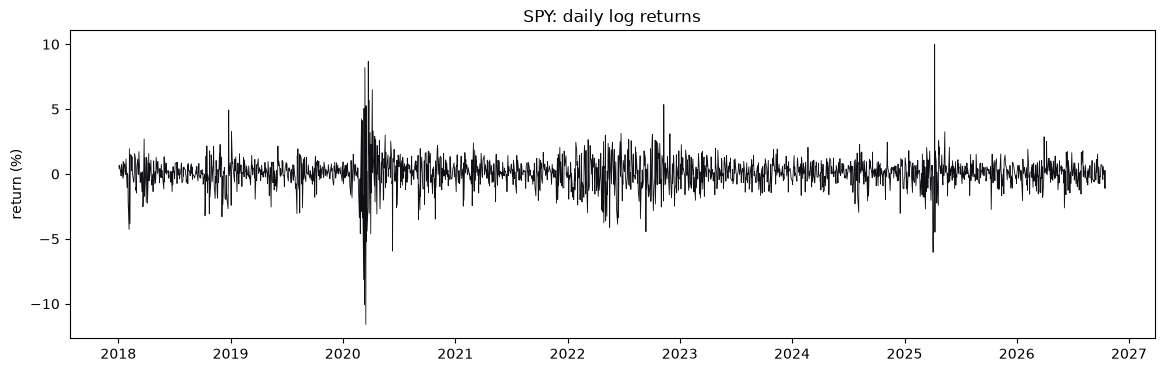

In [5]:
import warnings
import yfinance as yf

warnings.filterwarnings("ignore", module="yfinance")    # pandas deprecation notices from inside yfinance
# fixed dates, so the numbers below stay the same on every run
prices = yf.download("SPY", start="2018-01-01", end="2026-10-17", auto_adjust=True, progress=False)["Close"]["SPY"]
returns = 100 * np.log(prices).diff().dropna()
X = returns.to_numpy().reshape(-1, 1)        # hmmlearn wants one row a day
print(f"{len(returns)} trading days, {returns.index[0].date()} to {returns.index[-1].date()}")
print(f"mean {returns.mean():.3f}%, standard deviation {returns.std():.3f}%")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(returns, color=CALM, lw=0.6)
ax.set(title="SPY: daily log returns", ylabel="return (%)")
plt.show()

## 4. Learning: Baum-Welch, from several starts

`fit` runs Baum-Welch.
It climbs to the nearest local maximum of $p(\mathbf{x} \mid M)$, so we start it from 10 random places and keep the best fit.
`score` is the forward algorithm's $\log p(\mathbf{x} \mid M)$.

Baum-Welch does not know which state is which: state 0 of one fit may be state 1 of another.
So once it is done we **name the states ourselves**, by their spread.

In [6]:
def fit_best(K, X, starts=10, **options):
    """Baum-Welch from several random starts; the fit with the highest log p(x | M), and all the scores."""
    fits = [GaussianHMM(n_components=K, covariance_type="diag", n_iter=1000, random_state=seed, **options).fit(X)
            for seed in range(starts)]
    scores = [m.score(X) for m in fits]
    return fits[int(np.argmax(scores))], scores


def in_order(model):
    """The states from the calmest to the wildest."""
    return np.argsort(model.covars_.ravel())


model, scores = fit_best(2, X)
print("log p(x | M) of the 10 starts:", np.round(scores, 1))
order = in_order(model)
calm, turbulent = order
sd = np.sqrt(model.covars_.ravel())
for name, s in [("calm", calm), ("turbulent", turbulent)]:
    print(f"{name:>9}: mean {model.means_.ravel()[s]:+.3f}%, standard deviation {sd[s]:.2f}%, "
          f"stays with probability {model.transmat_[s, s]:.4f}, "
          f"{1 / (1 - model.transmat_[s, s]):.0f} days on average")

log p(x | M) of the 10 starts: [-3077.6 -3077.6 -3077.6 -3077.6 -3077.6 -3077.6 -3077.6 -3077.6 -3077.6
 -3077.6]
     calm: mean +0.120%, standard deviation 0.70%, stays with probability 0.9815, 54 days on average
turbulent: mean -0.144%, standard deviation 2.04%, stays with probability 0.9452, 18 days on average


Both means are close to zero; what tells the two states apart is the **spread**: a turbulent day moves the market about three times as much as a calm one.
That is why we call them calm and turbulent rather than bull and bear.

A state that stays with probability $a_{ii}$ lasts $1 / (1 - a_{ii})$ days on average: its stays are geometric.

## 5. Decoding: Viterbi and forward-backward

Two questions, two answers:

- `predict` runs **Viterbi**: the single most likely sequence of states for all the days together.
- `predict_proba` runs **forward-backward**: $\gamma_t(i) = p(h_t = s_i \mid \mathbf{x})$, day by day, using the returns before **and after** each day.

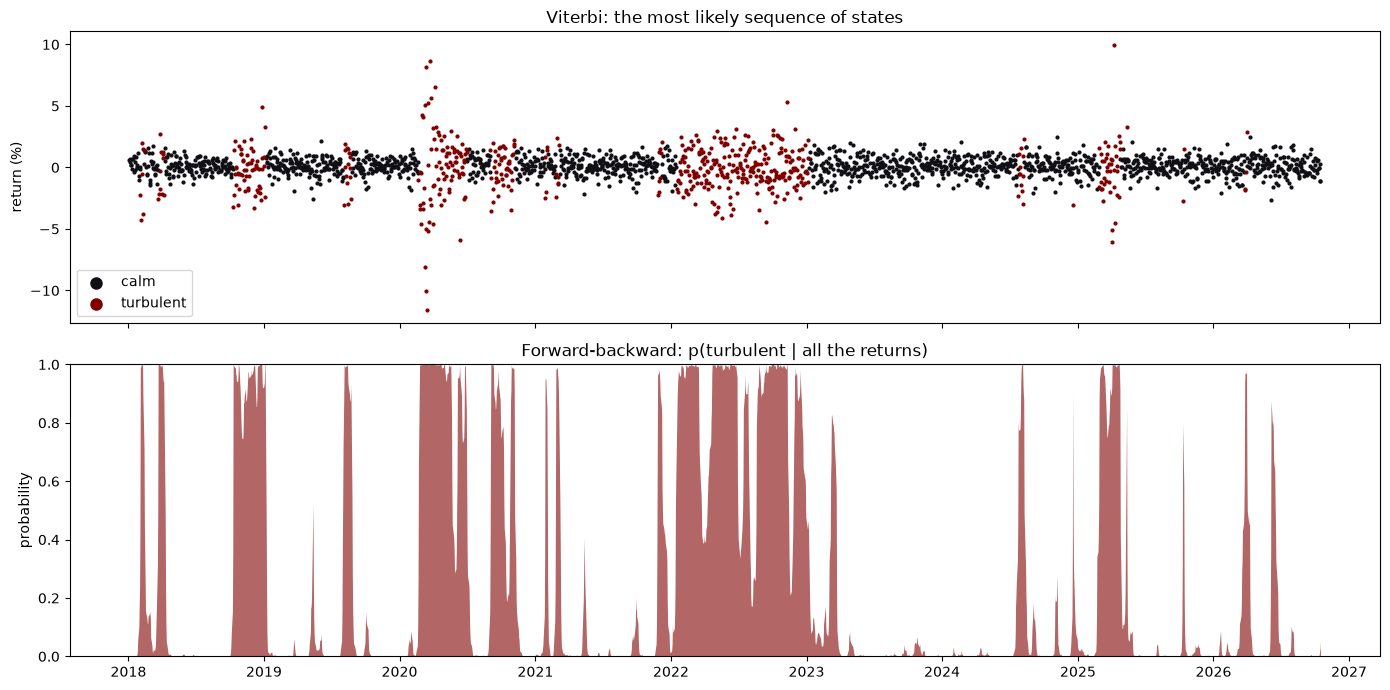

Viterbi calls 554 days turbulent; p(turbulent | x) > 0.5 on 523 days.
They disagree on 99 days: the best sequence is not the sequence of the best days.


In [7]:
states = model.predict(X)                       # Viterbi
p_turbulent = model.predict_proba(X)[:, turbulent]  # forward-backward

fig, (top, bottom) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for s, color, name in [(calm, CALM, "calm"), (turbulent, TURBULENT, "turbulent")]:
    top.scatter(returns.index[states == s], returns[states == s], s=4, color=color, label=name)
top.set(title="Viterbi: the most likely sequence of states", ylabel="return (%)")
top.legend(loc="lower left", markerscale=4)
bottom.fill_between(returns.index, p_turbulent, color=TURBULENT, alpha=0.6, lw=0)
bottom.set(title="Forward-backward: p(turbulent | all the returns)", ylabel="probability", ylim=(0, 1))
plt.tight_layout()
plt.show()

disagree = (states == turbulent) != (p_turbulent > 0.5)
print(f"Viterbi calls {np.sum(states == turbulent)} days turbulent; p(turbulent | x) > 0.5 on {np.sum(p_turbulent > 0.5)} days.")
print(f"They disagree on {disagree.sum()} days: the best sequence is not the sequence of the best days.")

The turbulent spells Viterbi finds, the longest first:

In [8]:
def spells(states, state, dates):
    """The runs of `state` in the Viterbi sequence: first day, last day and length."""
    runs, start = [], None
    for t, s in enumerate(np.append(states, -1)):
        if s == state and start is None:
            start = t
        elif s != state and start is not None:
            runs.append((dates[start].date(), dates[t - 1].date(), t - start))
            start = None
    return pd.DataFrame(runs, columns=["first day", "last day", "days"]).sort_values("days", ascending=False)


spells(states, turbulent, returns.index).head(8).reset_index(drop=True)

,first day,last day,days
0,2022-01-18,2023-01-06,245
1,2020-02-21,2020-06-30,91
2,2018-10-10,2019-01-04,59
3,2020-09-02,2020-11-05,46
4,2025-02-27,2025-04-24,40
5,2019-08-05,2019-08-23,15
6,2024-07-24,2024-08-08,12
7,2018-03-22,2018-04-06,11


## 6. How many states?

More states always fit at least as well, so $\log p(\mathbf{x} \mid M)$ alone would always ask for more.
The Bayesian answer compares the evidence $p(\mathbf{x} \mid K)$, which charges for every extra parameter.
The **BIC** approximates $-2 \log p(\mathbf{x} \mid K)$:

$$\mathrm{BIC} = -2 \log p(\mathbf{x} \mid \hat{M}_K) + d_K \log T, \qquad d_K = K^2 + 2K - 1 \text{ free parameters.}$$

The lower the better.
$K = 1$ is a single Normal for every day: no hidden state at all.

In [9]:
rows = []
for K in range(1, 5):
    best, scores = fit_best(K, X)
    rows.append({"K": K, "log p(x | M)": best.score(X), "free parameters": K * K + 2 * K - 1, "BIC": best.bic(X),
                 "spread of the 10 starts": max(scores) - min(scores)})
table = pd.DataFrame(rows).set_index("K").round(1)
table

,log p(x | M),free parameters,BIC,spread of the 10 starts
K,,,,
1,-3531.7,2,7078.7,0.0
2,-3077.6,7,6209.0,0.0
3,-2974.8,14,6057.5,0.2
4,-2945.8,23,6068.8,107.6


The log-likelihood keeps rising with $K$, but the BIC is lowest at $K = 3$: a third state pays for its 7 extra parameters, a fourth state's 9 more do not pay.

The last column is the gap between the best and the worst of the 10 starts.
With 4 states, Baum-Welch lands on different hill tops from different starts: that is why we restart it.

## 7. A prior on the moves

hmmlearn's Baum-Welch takes a Dirichlet prior on each row of $A$, `transmat_prior`.
Its entries minus one are **pseudo-counts**, added to the expected number of moves in the maximization step: a prior is pseudo-observations, as in week 4.

Suppose we believed that a regime lasts about 100 days, and trusted that belief as much as 1000 moves out of each state.
The fit becomes the posterior mode, $\arg\max_M p(M \mid \mathbf{x})$.

hmmlearn checks that $p(\mathbf{x} \mid M)$ rises at every step, but with a prior Baum-Welch climbs $p(M \mid \mathbf{x})$ instead, so $p(\mathbf{x} \mid M)$ may dip a little.
We silence that warning.

In [10]:
logging.getLogger("hmmlearn").setLevel(logging.ERROR)

stay = 1 - 1 / 100                                    # a regime lasts 100 days
prior = 1 + 1000 * np.array([[stay, 1 - stay], [1 - stay, stay]])
believer, _ = fit_best(2, X, transmat_prior=prior)

for name, m in [("no prior", model), ("the prior", believer)]:
    o = in_order(m)
    days = 1 / (1 - np.diag(m.transmat_)[o])
    print(f"{name:>9}: calm lasts {days[0]:.0f} days, turbulent {days[1]:.0f} days, "
          f"log p(x | M) = {m.score(X):.1f}")

 no prior: calm lasts 54 days, turbulent 18 days, log p(x | M) = -3077.6
the prior: calm lasts 80 days, turbulent 49 days, log p(x | M) = -3082.6


The prior pulls the turbulent spells from about 18 days toward 100, because 1000 pseudo-moves outweigh the few hundred turbulent days in the data; the calm state, with more data, moves less.
A confident prior is many pseudo-observations, as in week 4.

## Try it

1. Fit $K = 3$ and name the states. What is the third one?
2. Change `"SPY"` for another ticker in the data cell (for example `"XLE"`, an energy fund; change both places it appears). Are its regimes the same days?
3. Take the moody friend's `friend` model and decode a week: shop, shop, clean, shop, walk, walk, clean.